# Assignment 08: Species Distribution Modeling with elapid

## BIO597 Spatial Analysis of Biodiversity

Use `elapid` to prepare spatial data, fit a MaxEnt model, and ask how evaluation changes when we withhold whole geographic areas. You may reuse code from Lab08.

## Deliverable

Submit this completed notebook with maps, climate comparisons, ROC curves, an AUC summary table, and short written answers. Save your modeling points and AUC table. Use the lab's model defaults; no parameter search or suitability-raster export is required.


## 1. Import packages and load the occurrence records

Run this notebook from `docs/assignments`. The imports are provided so you can focus on the SDM workflow. If elapid is unavailable, use the same environment or installation instructions as the lab.

`np.random.seed(597)` makes the background draws repeatable when the notebook runs from top to bottom.


In [2]:
import elapid as ela
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import plot as rioplot
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay

np.random.seed(597)
amphibians = gpd.read_file("../data/amphibians.geojson")
amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 2. Choose a species

Choose a common Maine amphibian other than the lab's pickerel frog (*Lithobates palustris*). Start with at least 200 records. Filter the occurrence table to your species and store the result as `species_points`.


In [3]:
target_species = "Pseudacris crucifer"

# Select your species and store a copy as species_points.
species_points = amphibians[amphibians["species"] == target_species].copy()

# Print the record count and coordinate reference system.
print("Number of records:", len(species_points))
print("CRS:", amphibians.crs)

Number of records: 1839
CRS: EPSG:4326


**Why this species?** Give one biological reason for your choice.
                                                 - The spring peeper is a widespread frog native to eastern North America. It has the largest numbers of observations in this dataset.

## 3. Set up the climate rasters

Use the same 19 Maine bioclimatic rasters as the lab. The filenames and readable column names are provided below. Their order matters: each label must describe the corresponding raster.


In [4]:
bioclim_names = {
    'wc2.1_2.5m_bio_1.tif':  'Annual mean temperature',
    'wc2.1_2.5m_bio_2.tif':  'Mean diurnal temperature range',
    'wc2.1_2.5m_bio_3.tif':  'Isothermality',
    'wc2.1_2.5m_bio_4.tif':  'Temperature seasonality',
    'wc2.1_2.5m_bio_5.tif':  'Max temperature, warmest month',
    'wc2.1_2.5m_bio_6.tif':  'Min temperature, coldest month',
    'wc2.1_2.5m_bio_7.tif':  'Annual temperature range',
    'wc2.1_2.5m_bio_8.tif':  'Mean temperature, wettest quarter',
    'wc2.1_2.5m_bio_9.tif':  'Mean temperature, driest quarter',
    'wc2.1_2.5m_bio_10.tif': 'Mean temperature, warmest quarter',
    'wc2.1_2.5m_bio_11.tif': 'Mean temperature, coldest quarter',
    'wc2.1_2.5m_bio_12.tif': 'Annual precipitation',
    'wc2.1_2.5m_bio_13.tif': 'Precipitation, wettest month',
    'wc2.1_2.5m_bio_14.tif': 'Precipitation, driest month',
    'wc2.1_2.5m_bio_15.tif': 'Precipitation seasonality',
    'wc2.1_2.5m_bio_16.tif': 'Precipitation, wettest quarter',
    'wc2.1_2.5m_bio_17.tif': 'Precipitation, driest quarter',
    'wc2.1_2.5m_bio_18.tif': 'Precipitation, warmest quarter',
    'wc2.1_2.5m_bio_19.tif': 'Precipitation, coldest quarter',
}

rasters = [f"../data/bioclim_ME/{var}" for var in bioclim_names]
labels = list(bioclim_names.values())

## 4. Map the records over temperature

Open `rasters[0]` (annual mean temperature), plot it with `rioplot.show()`, and overlay your species' points. Reproject the points to the raster CRS when plotting, as in the lab. Keep this first raster path as `mean_temp_raster` for sampling.


/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


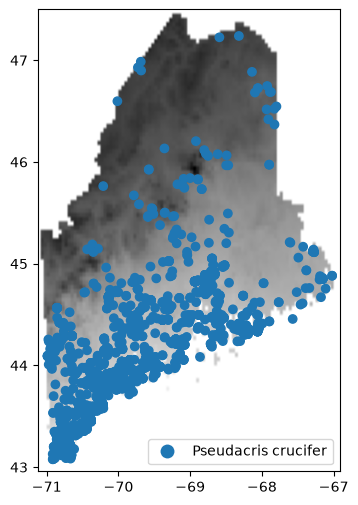

In [5]:
mean_temp_raster = rasters[0]

fig, ax = plt.subplots(figsize=(6,6))

with rio.open(mean_temp_raster, 'r') as src:
    rioplot.show(src, ax=ax, cmap="gray")
    species_points.to_crs(src.crs).plot(column='species', ax=ax, legend=True)

**Interpretation:** Are records spread across Maine or concentrated in particular places? Why might a gap in records fail to indicate a true absence?
- There are some notable gaps in the records. There is are large gap in eastern (inland) and northern Maine. There appears to be a cluster along the coast particularly in southern Maine. These gaps could correspond with very remote areas that are hard to sample/observe and not reflect true absences.

## 5. Compare two background samples

Draw 1,000 points with `ela.sample_raster()` and another 1,000 with `ela.sample_bias_file()`, using annual mean temperature as the bias file. Drop duplicate geometries in each sample, following the lab, and report the remaining counts. Map the two samples side by side.

The biased sample favors cells with larger temperature values. This is a demonstration of sampling bias; temperature alone does not establish where observers actually searched.


count                                     917
unique                                    917
top       POINT (-67.1875 45.104166666666664)
freq                                        1
dtype: object

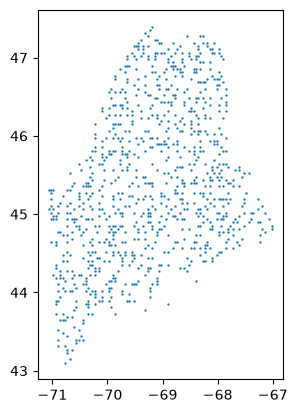

In [6]:
count = 1000

# Create pseudoabsence with ela.sample_raster().
# Create pseudoabsence_bias with ela.sample_bias_file().
# Drop duplicate points, print the remaining counts, and map both samples.

pseudoabsence = ela.sample_raster(mean_temp_raster, count)
pseudoabsence.drop_duplicates(inplace=True)
pseudoabsence.plot(markersize=0.5)
pseudoabsence.describe()

count                                   1000
unique                                   908
top       POINT (-68.14583333333333 44.6875)
freq                                       4
dtype: object

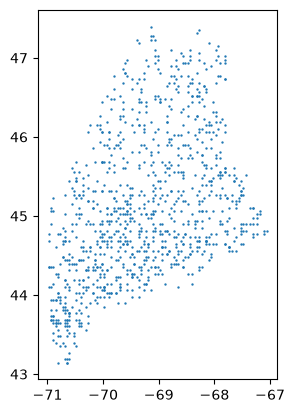

In [7]:
mean_temp_raster = rasters[0]
pseudoabsence_bias = ela.sample_bias_file(mean_temp_raster, count)
pseudoabsence_bias.plot(markersize=0.5)
pseudoabsence_bias.describe()

**Interpretation:** How do the two geographic samples differ? Explain why background choice can change the species–climate relationship learned by a model. 
- The 'pseudoabsence' samples are created from a random geographic sampling throughout the target landscape. The 'pseudoabsence_bias' uses a raster to add probability of sampling a particular area. This inclusion of samplign bias is recommended because species occurrence records are expected to be biased towards certain geographic locations. In this example, we are using mean temperature because we think observers are more likely to look for the amphibians in relatively warmer areas. 

Choose one sample for the remaining analysis and keep it fixed. The line below uses the uniform sample; change it to `pseudoabsence_bias` if you choose the biased sample.

**Background choice and justification:**
- I'm choosing to use the bias set for the background points because I expect that there will be a noteable amount of sampling bias in these occurrence records and want this to be replicated in the background points.


In [8]:
background_points = pseudoabsence_bias

## 6. Extract climate values with `ela.annotate()`

Annotate `species_points.geometry` and your chosen `background_points` using `rasters`, `labels`, `drop_na=True`, and `quiet=True`. Store the results as `presence` and `background`. Report the number of usable rows in each table.

Annotation means extracting raster values at point locations. `drop_na=True` removes points falling on raster NoData cells.


In [9]:
# Annotate presence and background points, following Lab08.
# Print the usable counts and display presence.head().

presence = ela.annotate(
    species_points.geometry,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

background = ela.annotate(
    pseudoabsence_bias,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

print("Presence counts:", len(presence))
print("Background counts:", len(background))
presence.head()

Presence counts: 1722
Background counts: 1000


,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter","Mean temperature, coldest quarter",Annual precipitation,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry
0,6.033667,12.406000,30.341421,1008.109314,26.004,-14.884,40.888000,1.446000,-5.662000,18.181999,-6.827333,1126.0,117.0,77.0,11.435465,314.0,244.0,295.0,256.0,POINT (-70.85036 44.27281)
1,7.499833,10.227667,27.609510,951.310608,25.848,-11.196,37.043999,3.229333,18.366667,19.057333,-4.544000,1155.0,120.0,79.0,13.698776,334.0,245.0,254.0,294.0,POINT (-69.96887 43.88746)
2,5.654500,11.792334,28.162813,1060.219482,26.100,-15.772,41.872002,1.019333,-6.686000,18.416000,-7.943334,1099.0,111.0,71.0,11.360600,304.0,232.0,283.0,255.0,POINT (-68.45989 45.3059)
3,6.012000,12.240000,29.499662,1031.210205,26.180,-15.312,41.492001,1.479333,-5.998667,18.380001,-7.231333,1141.0,107.0,72.0,9.757760,306.0,254.0,292.0,257.0,POINT (-70.07333 44.59266)
4,6.190166,10.291666,28.289352,928.378540,24.104,-12.276,36.380001,-2.726667,17.236666,17.236666,-5.690667,1196.0,121.0,77.0,14.983714,352.0,241.0,241.0,316.0,POINT (-67.11095 44.75506)


## 7. Compare recorded and available environments

Use the plotting recipe below to compare annual mean temperature, annual precipitation, and precipitation seasonality. These are the same three variables considered in Lab07. Density-scaled histograms let us compare shapes despite different sample sizes.


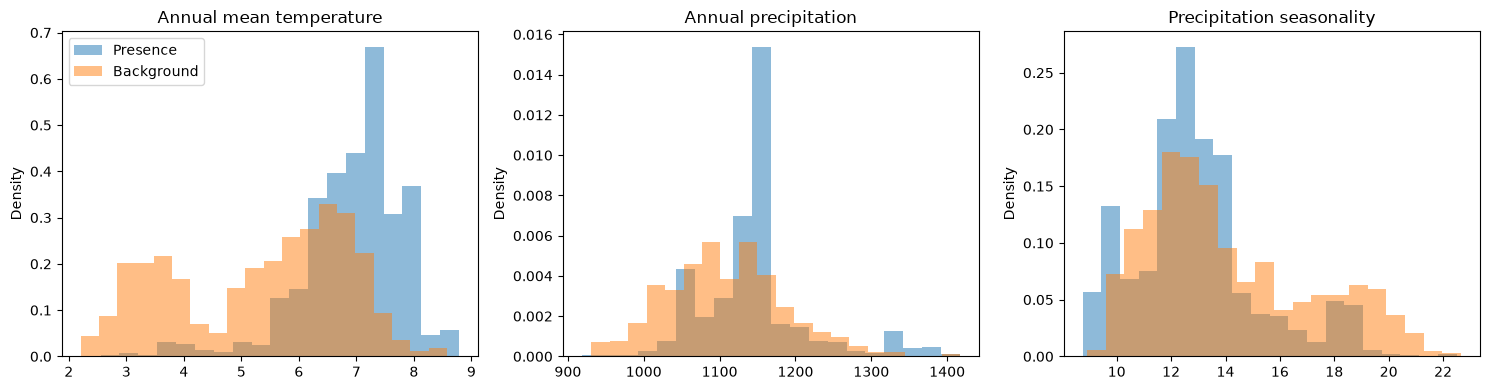

In [10]:
comparison_labels = [labels[0], labels[11], labels[14]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, ax in zip(comparison_labels, axes):
    ax.hist(presence[label], bins=20, density=True, alpha=0.5, label="Presence")
    ax.hist(background[label], bins=20, density=True, alpha=0.5, label="Background")
    ax.set_title(label)
    ax.set_ylabel("Density")

axes[0].legend()
plt.tight_layout()
plt.show()


**Interpretation:** Choose one variable. Does your species' recorded environment differ from the sampled background? Describe the pattern without assuming it proves a habitat preference.
- Annual Mean Temperature shows the most distince difference: The presence records are more narrow and are clustered in warmer temperatures relative to the background records. The background record distrubtion appears bimodal and has a broader distribution. This does not necessarily indicated habitat preference because the records could be from a biased sampling effort, or the background could include areas that are unrealistic for the species to occur.

## 8. Calculate geographic sample weights

Following the lab, use `ela.distance_weights(..., n_neighbors=-1)` to calculate a `SampleWeight` column separately for presence and background. Pass points projected to `EPSG:26919`, which uses meters. Plot presence points colored by their weights.

The weights give relatively isolated observations more influence than observations in dense clusters. They do not turn an unobserved location into a confirmed absence.


<Axes: >

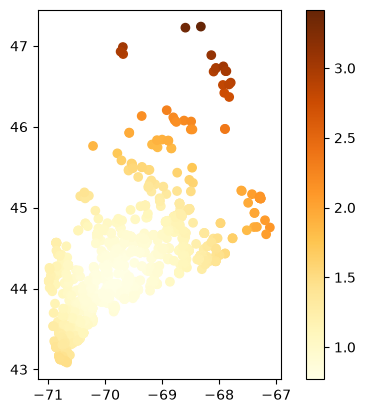

In [11]:
# Calculate presence["SampleWeight"] using presence.to_crs("EPSG:26919").
# Calculate background["SampleWeight"] the same way.
# Plot the presence weights with a legend.

presence['SampleWeight'] = ela.distance_weights(presence.to_crs('EPSG:26919'), n_neighbors=-1)
background['SampleWeight'] = ela.distance_weights(background.to_crs('EPSG:26919'), n_neighbors=-1)
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')

**Interpretation:** Where are the largest weights? Why would decimal degrees be a poor unit for the distance calculations?
- The points farthest away from other points hold the highest weight. This is what we want to see because points spatially close to each other can artificially inflate similar information.
- If we used decimal degrees, it would be distorted on the ground because of the angles as you move N/S. UTM is a better choice because the units are in meters and there is very little distortion within a zone. 

## 9. Stack the tables and define predictors

Use `ela.stack_geodataframes(presence, background, add_class_label=True)` and project the result to `EPSG:26919`. Call the result `merged` and display the counts in its `class` column.

`class` is 1 for presence and 0 for background. Select only the named climate columns as predictors. `SampleWeight`, class labels, geometry, and later split labels must stay out of the predictor table.


In [12]:
# Stack presence and background as merged, then project it to EPSG:26919.
# Display the counts of each class.

merged = ela.stack_geodataframes(
    presence,
    background,
    add_class_label=True,
).to_crs('EPSG:26919')

X = merged[labels]
y = merged["class"]
sample_weight = merged["SampleWeight"]

merged.head()


,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter",...,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry,SampleWeight,class
0,6.033667,12.406000,30.341421,1008.109314,26.004,-14.884,40.888000,1.446000,-5.662000,18.181999,...,117.0,77.0,11.435465,314.0,244.0,295.0,256.0,POINT (352329.685 4903838.736),1.140814,1
1,7.499833,10.227667,27.609510,951.310608,25.848,-11.196,37.043999,3.229333,18.366667,19.057333,...,120.0,79.0,13.698776,334.0,245.0,254.0,294.0,POINT (422174.953 4859829.831),0.802961,1
2,5.654500,11.792334,28.162813,1060.219482,26.100,-15.772,41.872002,1.019333,-6.686000,18.416000,...,111.0,71.0,11.360600,304.0,232.0,283.0,255.0,POINT (542341.705 5017074.922),1.593975,1
3,6.012000,12.240000,29.499662,1031.210205,26.180,-15.312,41.492001,1.479333,-5.998667,18.380001,...,107.0,72.0,9.757760,306.0,254.0,292.0,257.0,POINT (414808.115 4938262.647),0.944619,1
4,6.190166,10.291666,28.289352,928.378540,24.104,-12.276,36.380001,-2.726667,17.236666,17.236666,...,121.0,77.0,14.983714,352.0,241.0,241.0,316.0,POINT (649519 4957476.278),2.118885,1


## 10. Fit MaxEnt and calculate a training AUC

Create `maxent = ela.MaxentModel()` and fit it with `X`, `y`, and `sample_weight=sample_weight`. Predict scores for `X`.

This first check uses the same rows for learning and evaluation, as in the lab's “naive” model. It is a **training score**, not a test of new locations.

**ROC AUC** measures how well scores rank presence above background. A value near 0.5 indicates little ranking ability; a higher value indicates better separation of these labels. The ROC curve shows the tradeoff as we change the cutoff for calling a score high: more recorded presences exceed the cutoff, but more background points may exceed it too. AUC does not establish true occupancy probability.


Unweighted naive AUC score: 0.908191637630662
Weighted naive AUC score  : 0.9009530320762977


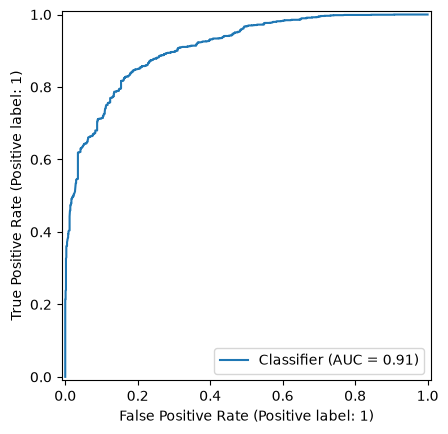

In [13]:
maxent = ela.MaxentModel()
maxent.set_params(n_cpus=4)
X = merged.drop(columns=['class', 'SampleWeight'])
y = merged['class']
sample_weight = merged['SampleWeight'] 

# Fit maxent with X, y, and sample_weight.
maxent.fit(X, y, sample_weight=sample_weight)

# Predict X and store the scores as naive_prediction.
naive_prediction = maxent.predict(X)

# Calculate naive_auc with metrics.roc_auc_score(y, naive_prediction).
naive_auc = metrics.roc_auc_score(y, naive_prediction)

# Also calculate naive_weighted_auc using sample_weight=sample_weight.
naive_weighted_auc = metrics.roc_auc_score(y, naive_prediction, sample_weight=sample_weight)

# Print both scores and plot a ROC curve with RocCurveDisplay.from_predictions().
print(f"Unweighted naive AUC score: {naive_auc}")
print(f"Weighted naive AUC score  : {naive_weighted_auc}")
RocCurveDisplay.from_predictions(y, naive_prediction)

**Interpretation:** Why might evaluating the same rows used to fit a model give an overly encouraging impression of performance?
- Because you would be testing on the training information, which is not actually testing at all. If you test the model on the exact info it has seen before, it should test very well.

## 11. Make a geographic train/test split

Use `ela.checkerboard_split(merged, grid_size=50_000)` to divide points into alternating 50 km squares. This distance is in meters because `merged` is projected.

Check the class counts in both groups: each needs presence and background rows to calculate AUC. The provided plotting recipe adds a split label for display only.


Training labels:
class
1    1084
0     487
Name: count, dtype: int64
Test labels:
class
1    636
0    513
Name: count, dtype: int64


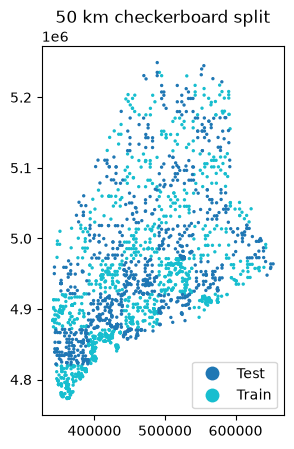

In [14]:
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)
print("Training labels:")
print(train["class"].value_counts())
print("Test labels:")
print(test["class"].value_counts())

train["split"] = "Train"
test["split"] = "Test"
checker = ela.stack_geodataframes(train, test)
checker.plot(column="split", markersize=2, legend=True)
plt.title("50 km checkerboard split")
plt.show()


## 12. Refit using training points and evaluate test points

Build training and test predictor tables using only `labels`, as below. Refit `maxent` on the training rows and their weights, then predict the test rows. Calculate unweighted and weighted test AUCs, storing them as `checker_auc` and `checker_weighted_auc`. Plot the test ROC curve.

In weighted AUC, test weights affect the contribution of each test row. They do not mean the model learned from the test labels.


Unweighted checkerboard AUC score: 0.6492408081699708
Weighted checkerboard AUC score  : 0.6603437283989098


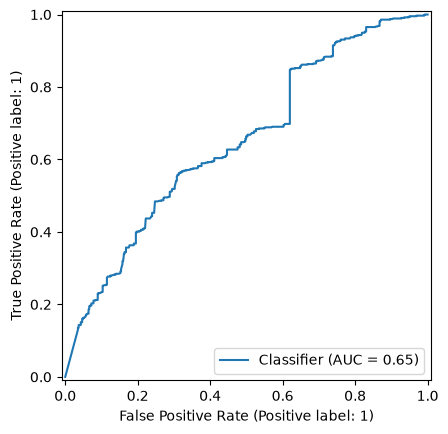

In [18]:
Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]
Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

# Fit maxent using only Xtrain, ytrain, and weight_train.
maxent.fit(Xtrain, ytrain, sample_weight=weight_train)

# Predict Xtest and calculate checker_auc and checker_weighted_auc.
ypred = maxent.predict(Xtest)
checker_auc = metrics.roc_auc_score(ytest, ypred)
checker_weighted_auc = metrics.roc_auc_score(ytest, ypred, sample_weight=weight_test)

# Print the scores and plot the test ROC curve.
print(f"Unweighted checkerboard AUC score: {checker_auc}")
print(f"Weighted checkerboard AUC score  : {checker_weighted_auc}")
RocCurveDisplay.from_predictions(ytest, ypred)

## Apply the trained model to the ME clipped rasters

<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:13: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_2581/3407716391.py:13: SyntaxWarning: invalid escape sequence '\ '
  ax.set_title('$Pseudacris\ crucifer$ suitability')


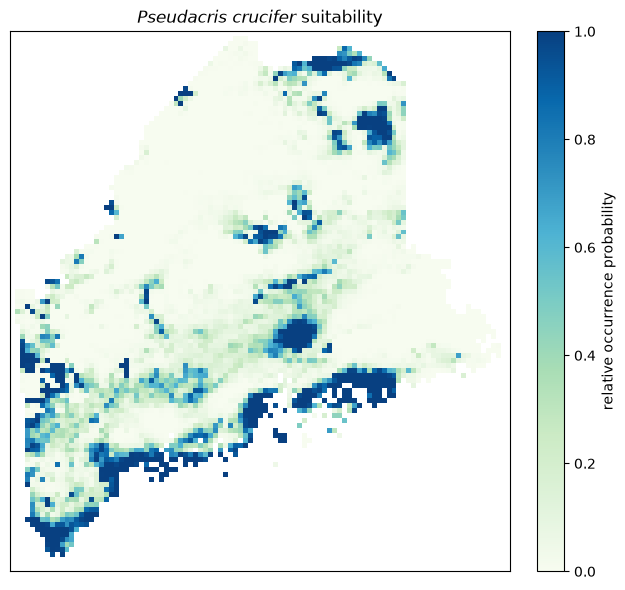

In [23]:
# Use ela.apply_model_to_rasters() to apply the fitted model to the raster stack
# and write the result to the output_raster file
output_raster = "Pseudacris_crucifer_predictions.tif"
ela.apply_model_to_rasters(maxent, rasters, output_raster, quiet=True)

# use rio.open() to read the predicted tif back into memory
# and plot it with imshow()
with rio.open(output_raster, 'r') as src:
    pred = src.read(1, masked=True)

fig, ax = plt.subplots(1, 1, figsize=(7, 6), dpi=100)
plot = ax.imshow(pred, vmin=0, vmax=1, cmap='GnBu')
ax.set_title('$Pseudacris\ crucifer$ suitability')
ax.set_xticks([])
ax.set_yticks([])
cbar = plt.colorbar(plot, ax=ax, label="relative occurrence probability", pad=0.04)
plt.tight_layout()

**Interpretation:** Did test AUC differ from training AUC? Describe what each score evaluates. A lower test score does not automatically prove that spatial autocorrelation caused the difference: the training size and environments also changed. A higher test score does not automatically establish a reliable map.
- Yes, the test AUC is much lower than the training AUC. The training AUC was calculated on the model fitted with all data and then tested against the same data. The test AUC was calculated on a model using only training data split using the checkerboard appraoch. The model was then tested agains data it had not be trained on. 

## 13. Give the other squares a turn

For a simple two-fold spatial cross-validation, reverse the roles: create a new MaxEnt model, train it using `Xtest`, `ytest`, and `weight_test`, then evaluate its predictions for `Xtrain`. Store the unweighted and weighted scores as `reverse_auc` and `reverse_weighted_auc`.

No new background draw or checkerboard split is needed.


In [24]:
# Create reverse_model with the same settings.
reverse_model = ela.MaxentModel()
reverse_model.set_params(n_cpus=4)

# Fit on Xtest with ytest and weight_test; predict Xtrain.
reverse_model.fit(Xtest, ytest, sample_weight=weight_test)
reverse_pred = reverse_model.predict(Xtrain)

# Calculate reverse_auc and reverse_weighted_auc against ytrain.
reverse_auc = metrics.roc_auc_score(ytrain, reverse_pred)
reverse_weighted_auc = metrics.roc_auc_score(ytrain, reverse_pred, sample_weight=weight_train)

# Print the scores.
print(f"Unweighted reverse AUC score: {reverse_auc}")
print(f"Weighted reverse AUC score  : {reverse_weighted_auc}")

Unweighted reverse AUC score: 0.7371435932018457
Weighted reverse AUC score  : 0.7297051975368598


**Interpretation:** Were the two directions equally easy to predict? Suggest one geographic or biological reason for a difference. Swapping the regions gives each group a turn as test data; it does not remove every source of observation bias.
- The reverse model resulted in a higher AUC. This might be due to the 50km squares and geographical/climate variation throughout the state. Looking back at the checkerboard map, a lot of the coastline is assiend to training set in the original model, which has a distinctly different climate than inland areas.

## 14. Inspect one buffered leave-one-out split

The lab also demonstrates buffered leave-one-out validation. For each test presence, it removes nearby training points so the model must predict farther from its training data.

Run the code below to inspect **one split**, using a 50 km buffer. No repeated model fitting is required here. `next()` takes just the first split that the splitter produces. This visualization is not a complete validation or an AUC estimate.


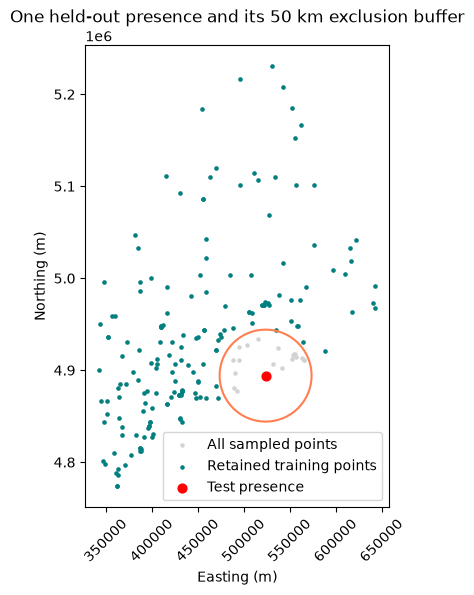

In [25]:
subset = merged.sample(n=min(200, len(merged)), random_state=597).reset_index(drop=True)
distance = 50_000
bloo = ela.BufferedLeaveOneOut(distance=distance)
train_idx, test_idx = next(bloo.split(subset, class_label="class"))
buffer_train = subset.iloc[train_idx]
buffer_test = subset.iloc[test_idx]

fig, ax = plt.subplots(figsize=(6, 6))
subset.plot(ax=ax, color="lightgray", markersize=5, label="All sampled points")
buffer_train.plot(ax=ax, color="teal", markersize=5, label="Retained training points")
buffer_test.buffer(distance).boundary.plot(ax=ax, color="coral")
buffer_test.plot(ax=ax, color="red", markersize=40, label="Test presence")
ax.legend()
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("One held-out presence and its 50 km exclusion buffer")
plt.show()

**Interpretation:** What happened to points inside the buffer? How does this test a different prediction question from randomly withholding records? Explain why a single held-out presence cannot by itself give a ROC AUC.
- The points inside the buffer were excluded from the training set. 
- This buffer helps reduce spatial autocorrelation. 
- Because you need more data points/scores to calculate ROC AUC. To actually perform leave-one-out cross-validation, we would repeat this process. This is an example and stopped at the first split. 

## 15. Summarize and save your results

Make a three-row table with evaluation names, unweighted AUCs, and weighted AUCs:

* Training rows scored by the all-data model.
* First checkerboard direction: train on `train`, evaluate `test`.
* Reversed direction: train on `test`, evaluate `train`.

Save it as `Assignment08_auc_scores.csv`, without a DataFrame index. Save `merged` as `Assignment08_modeling_points.gpkg` using `driver="GPKG"`, preserving its geometry, climate columns, labels, weights, and projected CRS.


In [26]:
# Build an AUC summary table from the six scores you stored.
auc_table = pd.DataFrame({
    "evaluation": [
        "All-data model",
        "Checkerboard (Train on train, evaluate test)",
        "Reverse (Train on test, evaluate train)",
    ],
    "unweighted_auc": [naive_auc, checker_auc, reverse_auc],
    "weighted_auc": [naive_weighted_auc, checker_weighted_auc, reverse_weighted_auc],
})

# Display it and save it to Assignment08_auc_scores.csv.
print(auc_table)
auc_table.to_csv("Assignment08_auc_scores.csv", index=False)

# Save merged to Assignment08_modeling_points.gpkg.
merged.to_file("Assignment08_modeling_points.gpkg", driver="GPKG")

                                     evaluation  unweighted_auc  weighted_auc
0                                All-data model        0.908192      0.900953
1  Checkerboard (Train on train, evaluate test)        0.649241      0.660344
2       Reverse (Train on test, evaluate train)        0.737144      0.729705


## Final reflection

Answer each question in two or three sentences, using your results.

1. Which preparation tasks did elapid simplify compared with earlier labs?
- A lot! Getting the climate values, background sampling, annotating, weighting, splitting.
2. What do background sampling, geographic sample weights, and spatial train/test splitting each change?
- Background sampling: changes what points are considered as available environments. 
- Geographic sample weights: changes how much influence a given row has relative to others.
Spatial train/test splitting: categorizes test/train points based on location instead of randomly to reduce spatial autocorrelation. The model is tested on geographic areas that it has not seen.
    
3. Why do high AUC and a convincing ROC curve not establish a probability that your species occurs at a location?
- Background points are not confirmed absences and this does not reflect sampling bias. AUC is a ranking of whether presence records tend to score higher than the background points being used. A higher AUC can reflect an easier test, rather than better prediction in new areas. 

4. What additional data or evaluation would most improve confidence in predictions for your species?
- Inclusion of true absence data (if available) or other habitat predictors such as waterbody availability. 

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, AUC table, saved points, and written answers. Commit and push the completed notebook and the two output files to your class GitHub repository.

```bash
git add docs/assignments/Assignment-08-SDM-Software.ipynb docs/assignments/Assignment08_auc_scores.csv docs/assignments/Assignment08_modeling_points.gpkg
git commit -m "Complete elapid SDM assignment"
git push
```

## References

* [elapid geospatial tools](https://earth-chris.github.io/elapid/module/geo/)
* [elapid MaxEnt model](https://earth-chris.github.io/elapid/sdm/maxent/)
* [elapid spatial train/test splitting](https://earth-chris.github.io/elapid/module/train_test_split/)
